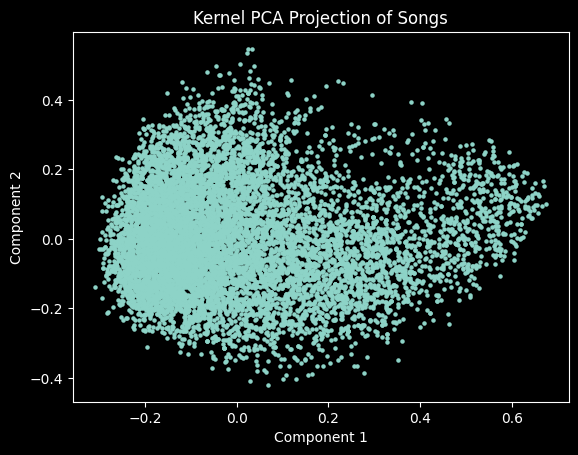

In [2]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
import numpy as np
from sklearn.decomposition import KernelPCA
import matplotlib.pyplot as plt

# Load in dataset
df = pd.read_csv("spotify.csv")

# drop rows of missing key identifiers
df = df.dropna(subset = ["track_name", "artists"])

#handle missing values
df = df.fillna(df.mean(numeric_only = True))

#convert bool to numeric
df["explicit"] = df["explicit"].astype(int)

# Drop non-useful 
drop_cols = [
    "track_id",
    "track_name",
    "artists",
    "album_name",
    "track_genre"
]

df_clean = df.drop(columns=drop_cols)

#select features
features = [
    "popularity",
    "duration_ms",
    "danceability",
    "energy",
    "key",
    "loudness",
    "mode",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "time_signature",
    "explicit"
]

X = df_clean[features]

#handle outliers
X = X.clip(lower=X.quantile(0.01),
           upper=X.quantile(0.99),
           axis=1)

#Normalize
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


# subset for kernal PCA
sample_size = 10000
df_sample = df.sample(sample_size, random_state=42)
df_sample = df_sample.copy()

X_sample = X_scaled[df_sample.index]

# apply kernel PCA
kpca = KernelPCA(
    n_components=2,
    kernel="rbf",
    gamma=0.01,
    random_state=42
)

X_kpca = kpca.fit_transform(X_sample)

# add back to df
df_sample["kpca_1"] = X_kpca[:, 0]
df_sample["kpca_2"] = X_kpca[:, 1]


plt.scatter(df_sample["kpca_1"], df_sample["kpca_2"], s=5)
plt.title("Kernel PCA Projection of Songs")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.show()

Reduced from 15 features to 12 components
Variance explained: 0.940


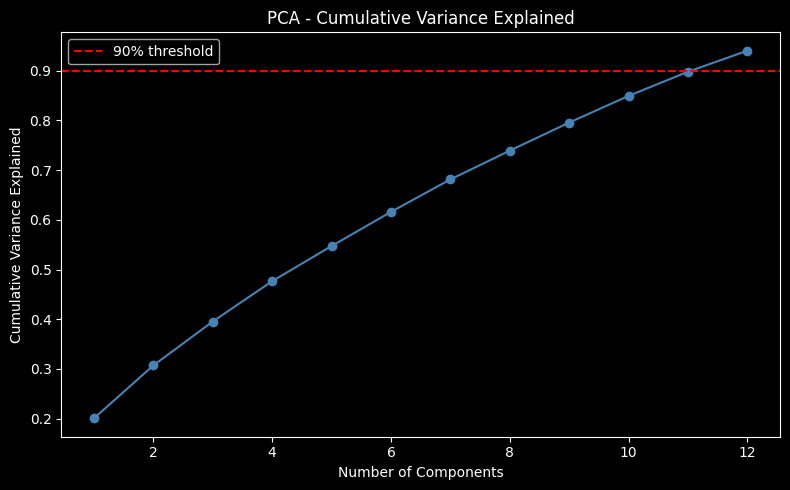

In [3]:
from sklearn.decomposition import PCA

# Run regular PCA on the full dataset (all 114,000 songs)
pca = PCA(n_components=0.90, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print(f"Reduced from {X_scaled.shape[1]} features to {X_pca.shape[1]} components")
print(f"Variance explained: {sum(pca.explained_variance_ratio_):.3f}")

# Variance explained plot
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', color='steelblue')
plt.axhline(y=0.90, color='red', linestyle='--', label='90% threshold')
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Variance Explained")
plt.title("PCA - Cumulative Variance Explained")
plt.legend()
plt.tight_layout()
plt.show()